# 06 — Deep Learning (FD001)

**Project:** Predictive Intelligence · **Phase 6**

## Objective

Notebook 05 set the bar: tree models on engineered features reach a test RMSE of about 14 to 15 cycles. This notebook asks whether neural networks that read 30-cycle sensor windows directly can do better, and at what cost.

Four architectures are compared under identical conditions:

1. **MLP** — a plain fully connected network.
2. **LSTM** — a recurrent network that reads the window cycle by cycle.
3. **GRU** — a lighter recurrent network.
4. **TCN** — a temporal convolutional network.

A Transformer is discussed but not trained here; section 3 explains why.

**Protocol (fixed before any training).**

- Same engines for every model: 80 for training, the fixed 20-engine hold-out (seed 42) for early stopping and for comparing models.
- Same windows, same RUL cap (125), same loss, same optimiser settings, same stopping rule.
- Every architecture is trained with **three different random seeds**, because a neural network's result depends on its random starting weights. A single run cannot tell a better architecture from a lucky start.
- The input design is chosen on the hold-out engines. Only then are the models scored on the test set, and all four are reported whatever the outcome.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

Training all the networks takes roughly half an hour on a laptop CPU. To keep the notebook practical, each finished run is saved (weights in `models/deep/`, training history in `experiments/deep_runs/`) and reloaded on later executions. Set `RETRAIN = True` to train everything again from scratch; with the same seeds the results should repeat.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src import config
from src.data.cmapss import add_training_rul, load_subset
from src.data.splits import holdout_engine_split
from src.evaluation.metrics import mae, nasa_score, rmse
from src.features.build import add_baseline_change, build_tabular_features, cap_rul, make_windows
from src.models.networks import MLPRegressor, RecurrentRegressor, TCNRegressor, count_parameters
from src.models.training import predict_rul, train_network
from src.visualization import theme

theme.apply_theme()

RETRAIN = False
SEEDS = [0, 1, 2]
WINDOW = config.SEQUENCE_WINDOW
weights_dir = project_root / "models" / "deep"
runs_dir = project_root / "experiments" / "deep_runs"
weights_dir.mkdir(parents=True, exist_ok=True)
runs_dir.mkdir(parents=True, exist_ok=True)

print("PyTorch", torch.__version__, "| CPU threads:", torch.get_num_threads())

PyTorch 2.15.0+cpu | CPU threads: 4


## 2. Preparing the windows

Each training example is a block of 30 consecutive cycles from one engine, labelled with the capped RUL at the last cycle (decision D-011).

**What goes into each cycle of the window?** Two designs are tested:

- **Sensors only:** the 14 scaled sensor readings.
- **Sensors + change from baseline:** the same 14 readings plus, for each, the change from that engine's own first-20-cycle average (28 channels).

Why the second might matter: notebook 04 found change-from-baseline to be the most valuable feature for tree models. A network looking at cycles 150–180 of an engine cannot work out that engine's starting level by itself, because the starting level is not inside the window. Either we supply it, or the network has to do without.

The scaler is fitted on the 80 training engines only.

In [2]:
train, test, test_rul = load_subset("FD001")
sensors = config.FD001_SENSORS
delta_columns = [f"{name}_delta" for name in sensors]

train_frame = add_baseline_change(add_training_rul(train), sensors, config.BASELINE_CYCLES)
train_frame["target"] = cap_rul(train_frame["rul"], config.RUL_CAP)
test_frame = add_baseline_change(test, sensors, config.BASELINE_CYCLES)

training_engines, validation_engines = holdout_engine_split(train_frame)
is_training = train_frame["engine_id"].isin(training_engines)

input_designs = {"sensors only": sensors, "sensors + change from baseline": sensors + delta_columns}


def prepare_windows(columns: list[str]) -> dict:
    # Scale with training-engine statistics, then cut windows for train, validation and test.
    scaler = StandardScaler().fit(train_frame.loc[is_training, columns])
    scaled_train, scaled_test = train_frame.copy(), test_frame.copy()
    scaled_train[columns] = scaler.transform(train_frame[columns])
    scaled_test[columns] = scaler.transform(test_frame[columns])

    x_train, y_train, _ = make_windows(scaled_train[is_training], columns, WINDOW, "target")
    x_validation, y_validation, _ = make_windows(scaled_train[~is_training], columns, WINDOW, "target")
    x_test, _, test_engine_ids = make_windows(scaled_test, columns, WINDOW, last_only=True)
    return {"x_train": x_train, "y_train": y_train, "x_validation": x_validation, "y_validation": y_validation,
            "x_test": x_test, "test_engine_ids": test_engine_ids, "channels": len(columns)}


datasets = {name: prepare_windows(columns) for name, columns in input_designs.items()}
for name, data in datasets.items():
    print(f"{name:32s} train {data['x_train'].shape}  validation {data['x_validation'].shape}  test {data['x_test'].shape}")

sensors only                     train (14459, 30, 14)  validation (3272, 30, 14)  test (100, 30, 14)
sensors + change from baseline   train (14459, 30, 28)  validation (3272, 30, 28)  test (100, 30, 28)


## 3. The architectures

**A few terms first.**

- A **neural network** is a chain of simple calculations with many adjustable numbers (*weights*). Training nudges the weights, a little at a time, to shrink the prediction error on the training examples.
- An **epoch** is one full pass over the training examples.
- **Overfitting** is when a network starts memorising the training engines instead of learning what generalises. Training error keeps falling while error on unseen engines rises.
- **Early stopping** guards against it: after each epoch we check the hold-out engines, and stop once they have not improved for 8 epochs, keeping the best version.
- **Dropout** randomly switches off part of the network during training so it cannot lean on any single path, another guard against memorising.

| | Idea | How it reads engine data | Strengths | Limits | Cost |
|---|---|---|---|---|---|
| **MLP** | Layers of weighted sums with a simple non-linearity between them | The 30×channels window is flattened into one long list; the network sees every reading at once | Simple, fast, a good check on whether order-aware models are needed at all | No built-in sense of time: it must learn from scratch that cycle 29 comes before cycle 30. Parameter count grows with window length | Lowest |
| **LSTM** | A recurrent network with a *memory cell* and gates that decide what to keep, forget and output | Reads one cycle at a time, updating a running summary of the engine's recent history | Designed for sequences; can carry a slow trend through many steps | Slow to train (steps cannot run in parallel); many settings; can be unstable | High |
| **GRU** | A simplified LSTM with two gates instead of three and no separate cell | Same cycle-by-cycle reading | Similar accuracy to LSTM in many problems with about a quarter fewer weights | Same sequential slowness | High |
| **TCN** | Stacked 1-D convolutions with widening gaps (*dilations*) and skip connections | Slides small filters along the time axis; deeper layers see wider stretches of history. Padding is on the past side only, so no output depends on future cycles | Trains in parallel, stable gradients, few weights | Its reach is fixed by the design; less established for this task | Medium |

**Why these suit the problem.** The signal is a slow drift hidden in noise (notebook 03), so anything that pools information across many cycles should help. All four can do that; they differ in how.

**Why not a Transformer now.** A Transformer uses *attention*: every cycle in the window can look directly at every other cycle and decide which matter. That flexibility pays off with long sequences, complex long-range structure, and large amounts of data. FD001 offers the opposite: about 14,000 heavily overlapping windows from 80 engines, each only 30 cycles long, containing a smooth one-directional trend (notebook 02 found one direction holds 64% of the variance). A Transformer would add many more weights and settings to tune with little for its attention to find, and the risk is fitting noise. It becomes worth testing on FD002 and FD004, where six flight conditions and two fault modes create structure that the simpler models may not capture. That is planned for Phase 9, not assumed here.

All networks use the same training recipe: Adam optimiser, learning rate 0.001, batches of 256 windows, mean-squared-error loss, at most 60 epochs. These are common starting values, not tuned.

In [3]:
def model_makers(channels: int) -> dict:
    return {
        "MLP": lambda: MLPRegressor(WINDOW, channels),
        "LSTM": lambda: RecurrentRegressor(channels, cell="lstm"),
        "GRU": lambda: RecurrentRegressor(channels, cell="gru"),
        "TCN": lambda: TCNRegressor(channels),
    }


def run_or_load(architecture: str, design: str, seed: int):
    # Train one network, or reload it if this exact run was already completed.
    data = datasets[design]
    make_model = model_makers(data["channels"])[architecture]
    run_name = f"fd001_{architecture.lower()}_{'delta' if 'baseline' in design else 'raw'}_seed{seed}"
    weights_path, history_path = weights_dir / f"{run_name}.pt", runs_dir / f"{run_name}.json"

    if weights_path.exists() and history_path.exists() and not RETRAIN:
        model = make_model()
        model.load_state_dict(torch.load(weights_path))
        history = json.loads(history_path.read_text())
    else:
        model, history = train_network(make_model, data["x_train"], data["y_train"], data["x_validation"],
                                       data["y_validation"], target_scale=config.RUL_CAP, seed=seed)
        history["parameters"] = count_parameters(model)
        torch.save(model.state_dict(), weights_path)
        history_path.write_text(json.dumps(history, indent=1))
    return model, history


pd.Series({name: count_parameters(make()) for name, make in model_makers(28).items()}, name="weights (28 input channels)").to_frame().T

,MLP,LSTM,GRU,TCN
weights (28 input channels),115969,59457,45121,25409


## 4. Experiment A — does the network need the engine's baseline?

Each architecture is trained once (seed 0) on each input design and compared on the hold-out engines.

In [4]:
ablation_rows = []
for design in input_designs:
    for architecture in ["MLP", "LSTM", "GRU", "TCN"]:
        _, history = run_or_load(architecture, design, seed=0)
        ablation_rows.append({"architecture": architecture, "input": design,
                              "validation RMSE": history["best_validation_rmse"]})

ablation = pd.DataFrame(ablation_rows).pivot(index="architecture", columns="input", values="validation RMSE")
ablation = ablation[list(input_designs)].loc[["MLP", "LSTM", "GRU", "TCN"]]
ablation["improvement"] = ablation["sensors only"] - ablation["sensors + change from baseline"]
ablation.round(2)

input,sensors only,sensors + change from baseline,improvement
architecture,,,
MLP,12.70,11.37,1.33
LSTM,13.66,10.92,2.73
GRU,12.91,10.72,2.20
TCN,14.08,11.28,2.80


**Findings.**

- **All four architectures improve when given the change-from-baseline channels**, by 1.3 to 2.8 cycles of validation RMSE. That is several times the seed-to-seed spread measured in the next section (about 0.2 to 0.3).
- The sequence models gain most (LSTM, GRU and TCN by 2.2 to 2.8), the MLP least (1.3).
- This repeats the finding from notebook 04 with a completely different kind of model: the engine's own starting level is information the model needs and cannot recover from a 30-cycle window.

**Decision.** The networks use 28 input channels: 14 scaled sensors plus their change from baseline. The decision is based on the hold-out engines only.

**Caveat.** One seed per cell. The gains are large compared with seed spread, so the direction is safe; the exact sizes are not.

## 5. Experiment B — comparing architectures over three seeds

With the input design chosen, each architecture is trained with seeds 0, 1 and 2. The spread across seeds tells us how much of any difference between architectures is just luck.

In [5]:
CHOSEN_DESIGN = "sensors + change from baseline"
architectures = ["MLP", "LSTM", "GRU", "TCN"]

runs = {(architecture, seed): run_or_load(architecture, CHOSEN_DESIGN, seed)
        for architecture in architectures for seed in SEEDS}

validation_summary = pd.DataFrame({
    architecture: {
        "validation RMSE (mean of 3 seeds)": np.mean([runs[architecture, s][1]["best_validation_rmse"] for s in SEEDS]),
        "spread across seeds (sd)": np.std([runs[architecture, s][1]["best_validation_rmse"] for s in SEEDS]),
        "best": np.min([runs[architecture, s][1]["best_validation_rmse"] for s in SEEDS]),
        "worst": np.max([runs[architecture, s][1]["best_validation_rmse"] for s in SEEDS]),
        "weights": runs[architecture, 0][1]["parameters"],
        "epochs to best (mean)": np.mean([runs[architecture, s][1]["best_epoch"] for s in SEEDS]),
        "training seconds (mean)": np.mean([runs[architecture, s][1]["seconds"] for s in SEEDS]),
    } for architecture in architectures
}).T
validation_summary.round(2)

,validation RMSE (mean of 3 seeds),spread across seeds (sd),best,worst,weights,epochs to best (mean),training seconds (mean)
MLP,11.12,0.19,10.91,11.37,115969.0,16.00,11.16
LSTM,10.84,0.25,10.50,11.09,59457.0,7.67,106.89
GRU,10.37,0.26,10.10,10.72,45121.0,12.67,179.89
TCN,11.37,0.17,11.23,11.61,25409.0,10.00,150.64


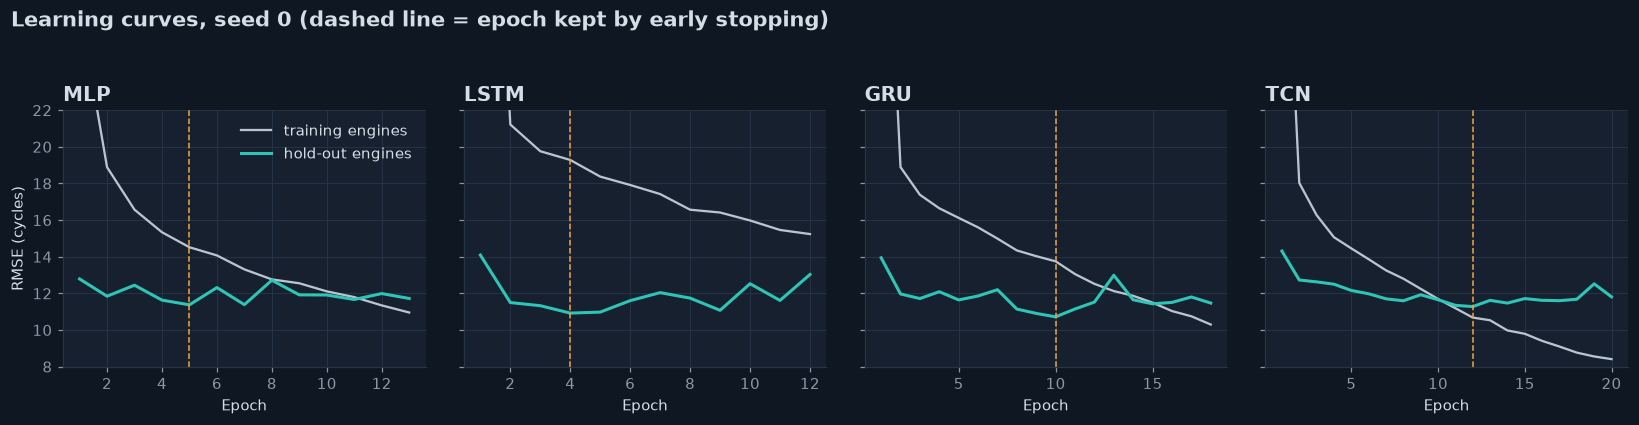

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
for ax, architecture in zip(axes, architectures):
    history = runs[architecture, 0][1]
    epochs = range(1, len(history["train_rmse"]) + 1)
    ax.plot(epochs, history["train_rmse"], color=theme.SILVER, label="training engines")
    ax.plot(epochs, history["validation_rmse"], color=theme.TEAL, linewidth=2, label="hold-out engines")
    ax.axvline(history["best_epoch"], color=theme.AMBER, linestyle="--", linewidth=1)
    ax.set_title(architecture)
    ax.set_xlabel("Epoch")
    ax.set_ylim(8, 22)
axes[0].set_ylabel("RMSE (cycles)")
axes[0].legend(loc="upper right")
fig.suptitle("Learning curves, seed 0 (dashed line = epoch kept by early stopping)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=theme.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### A like-for-like reference from notebook 05

The tree models in notebook 05 were trained on all 100 engines. For a fair comparison on the hold-out engines, XGBoost is retrained here on the same 80 training engines with the same settings and scored on exactly the rows the networks are scored on (the last cycle of every validation window).

In [7]:
tabular, tabular_features = build_tabular_features(
    add_training_rul(train), sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
tabular["target"] = cap_rul(tabular["rul"], config.RUL_CAP)
tabular_training = tabular[tabular["engine_id"].isin(training_engines)]
# A window ending at cycle c exists for every c >= 30, so these are the same prediction points.
tabular_validation = tabular[tabular["engine_id"].isin(validation_engines) & (tabular["cycle"] >= WINDOW)]

xgb_80 = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                      n_jobs=-1, random_state=config.RANDOM_SEED)
xgb_80.fit(tabular_training[tabular_features], tabular_training["target"])
xgb_validation_rmse = rmse(tabular_validation["target"],
                           np.clip(xgb_80.predict(tabular_validation[tabular_features]), 0, config.RUL_CAP))

print(f"Validation rows: {len(tabular_validation):,} (networks: {len(datasets[CHOSEN_DESIGN]['y_validation']):,})")
print(f"XGBoost trained on the same 80 engines, validation RMSE: {xgb_validation_rmse:.2f}")

Validation rows: 3,272 (networks: 3,272)
XGBoost trained on the same 80 engines, validation RMSE: 12.78


**Findings on the hold-out engines.**

- **All four networks beat the like-for-like XGBoost on the hold-out engines**: 10.4 to 11.4 against 12.8.
- **GRU has the lowest mean (10.4), then LSTM (10.8), MLP (11.1) and TCN (11.4).** The seed spread is about 0.2 to 0.3, so GRU's lead over MLP and TCN is probably real on these engines, while GRU against LSTM is closer to the noise.
- **The plain MLP is within one cycle of the best sequence model** and trains in about 11 seconds, against two to three minutes for the others. Knowing the order of the cycles adds little here.
- The learning curves show why early stopping is needed: training error keeps falling while hold-out error flattens and wobbles within a few epochs.

**An important warning before reading too much into this.** The hold-out engines were used to decide when to stop training each network. That makes the networks' hold-out scores somewhat optimistic: each network's best epoch was picked *because* it scored well on exactly these 20 engines. XGBoost had no such advantage. The test set, which played no part in training, is the fair comparison.

## 6. Final evaluation on the test set

Every network is scored on the 100 test engines, using each engine's most recent 30-cycle window. For each architecture we report:

- the **mean and spread over the three seeds**, which describes what a single trained network typically achieves, and
- the **seed ensemble**: the average of the three networks' predictions. Averaging independent models cancels part of their individual errors. It costs three times the computation.

The XGBoost model trained on the same 80 engines is included as the like-for-like reference. Truth is the RUL as given (up to 145); predictions are limited to 0–125.

In [8]:
test_data = datasets[CHOSEN_DESIGN]
true_rul = test_rul.set_index("engine_id").loc[test_data["test_engine_ids"], "true_rul"].to_numpy()

test_predictions, test_rows = {}, {}
for architecture in architectures:
    per_seed = np.stack([predict_rul(runs[architecture, s][0], test_data["x_test"], config.RUL_CAP) for s in SEEDS])
    ensemble = per_seed.mean(axis=0)
    test_predictions[architecture] = ensemble
    seed_rmse = [rmse(true_rul, p) for p in per_seed]
    seed_score = [nasa_score(true_rul, p) for p in per_seed]
    test_rows[architecture] = {
        "RMSE (mean of seeds)": np.mean(seed_rmse), "RMSE sd": np.std(seed_rmse),
        "NASA score (mean of seeds)": np.mean(seed_score), "NASA score sd": np.std(seed_score),
        "ensemble RMSE": rmse(true_rul, ensemble), "ensemble MAE": mae(true_rul, ensemble),
        "ensemble NASA score": nasa_score(true_rul, ensemble),
        "ensemble: late by more than 20": int((ensemble - true_rul > 20).sum()),
    }

tabular_test, _ = build_tabular_features(test, sensors, config.ROLLING_WINDOW, config.BASELINE_CYCLES)
tabular_test_last = tabular_test.groupby("engine_id").tail(1).set_index("engine_id").loc[test_data["test_engine_ids"]]
xgb_test = np.clip(xgb_80.predict(tabular_test_last[tabular_features]), 0, config.RUL_CAP)
test_predictions["XGBoost (80 engines)"] = xgb_test
test_rows["XGBoost (80 engines)"] = {
    "RMSE (mean of seeds)": rmse(true_rul, xgb_test), "NASA score (mean of seeds)": nasa_score(true_rul, xgb_test),
    "ensemble RMSE": np.nan, "ensemble MAE": mae(true_rul, xgb_test), "ensemble NASA score": np.nan,
    "ensemble: late by more than 20": int((xgb_test - true_rul > 20).sum()),
}

test_summary = pd.DataFrame(test_rows).T
test_summary.round(2)

,RMSE (mean of seeds),RMSE sd,NASA score (mean of seeds),NASA score sd,ensemble RMSE,ensemble MAE,ensemble NASA score,ensemble: late by more than 20
MLP,16.27,0.62,378.93,32.68,15.78,11.92,344.40,5.0
LSTM,17.00,0.85,435.32,43.31,16.37,12.65,387.48,4.0
GRU,16.36,0.78,401.91,66.59,16.01,11.93,374.68,7.0
TCN,16.78,0.66,422.02,61.92,16.29,12.03,375.83,4.0
XGBoost (80 engines),14.58,NaN,301.61,NaN,NaN,10.57,NaN,8.0


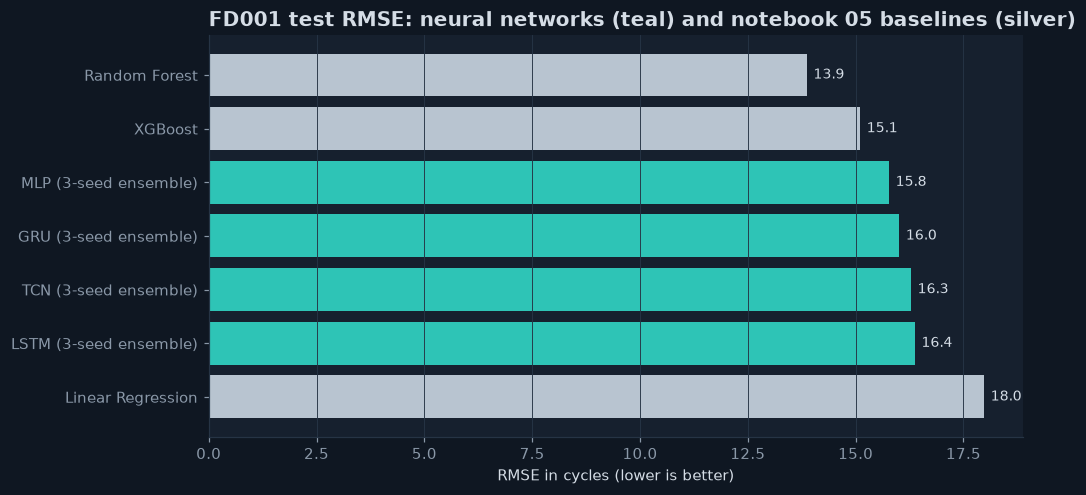

,RMSE,MAE,NASA score,trained_on
Random Forest,13.87,10.25,262.89,100 engines
XGBoost,15.11,10.84,321.86,100 engines
MLP (3-seed ensemble),15.78,11.92,344.40,80 engines
GRU (3-seed ensemble),16.01,11.93,374.68,80 engines
TCN (3-seed ensemble),16.29,12.03,375.83,80 engines
LSTM (3-seed ensemble),16.37,12.65,387.48,80 engines
Linear Regression,17.98,14.29,510.75,100 engines


In [9]:
baselines = pd.read_csv(project_root / "experiments" / "fd001_ml_baselines_test.csv", index_col="model")
comparison = pd.concat([
    baselines.loc[["Linear Regression", "Random Forest", "XGBoost"], ["RMSE", "MAE", "NASA score"]]
        .assign(trained_on="100 engines"),
    pd.DataFrame({
        "RMSE": test_summary.loc[architectures, "ensemble RMSE"],
        "MAE": test_summary.loc[architectures, "ensemble MAE"],
        "NASA score": test_summary.loc[architectures, "ensemble NASA score"],
    }).rename(index=lambda name: f"{name} (3-seed ensemble)").assign(trained_on="80 engines"),
]).sort_values("RMSE")

fig, ax = plt.subplots(figsize=(9.5, 4.6))
bar_colors = [theme.TEAL if "ensemble" in name else theme.SILVER for name in comparison.index]
ax.barh(comparison.index, comparison["RMSE"], color=bar_colors)
ax.invert_yaxis()
for position, value in enumerate(comparison["RMSE"]):
    ax.text(value + 0.15, position, f"{value:.1f}", va="center", color=theme.TEXT, fontsize=9)
ax.set_title("FD001 test RMSE: neural networks (teal) and notebook 05 baselines (silver)")
ax.set_xlabel("RMSE in cycles (lower is better)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

comparison.round(2)

In [10]:
bands = pd.cut(true_rul, bins=[0, 30, 60, 90, 125, 150], labels=["1-30", "31-60", "61-90", "91-125", "126-145"])
band_table = pd.DataFrame({"engines": pd.Series(true_rul).groupby(bands, observed=True).size()})
for name in architectures + ["XGBoost (80 engines)"]:
    error = pd.Series(test_predictions[name] - true_rul)
    band_table[f"{name} MAE"] = error.abs().groupby(bands, observed=True).mean()
band_table.round(1)

,engines,MLP MAE,LSTM MAE,GRU MAE,TCN MAE,XGBoost (80 engines) MAE
1-30,25,5.9,5.5,3.7,4.2,3.3
31-60,14,8.5,9.4,9.4,8.2,7.3
61-90,15,16.6,16.1,17.2,15.8,15.6
91-125,35,11.4,14.3,13.1,13.7,12.2
126-145,11,25.3,23.3,23.0,24.1,19.3


**Findings on the test set.**

- **The networks did not beat the tree models.** Single networks score a test RMSE of 16.3 to 17.0; the like-for-like XGBoost scores 14.6. Averaging three seeds helps (15.8 to 16.4) but does not close the gap. Random Forest from notebook 05 remains the best at 13.9.
- **The advantage seen on the hold-out engines did not carry over.** On the hold-out the networks led XGBoost by 1.4 to 2.4 cycles; on the test set they trail it by 1.2 to 2.4. This is what the warning above anticipated: the hold-out scores were flattered by early stopping on those same 20 engines, and 20 engines is a small sample.
- **The four architectures are indistinguishable on the test set.** Their means span 16.3 to 17.0 with seed spreads of 0.6 to 0.9. The ranking even changes: MLP is best on the test set, GRU was best on the hold-out. No architecture can be called better than another on this evidence.
- **Seed spread is larger on the test set than on the hold-out** (0.6 to 0.9 against 0.2 to 0.3). A single trained network can differ from its twin by more than a cycle for no reason other than its random start. Reporting one run would have been misleading.
- **Where the networks lose:** in the middle and upper ranges. For engines with more than 125 cycles left their average miss is 23 to 25 cycles against 19 for XGBoost. Near failure (1 to 30 cycles left) the GRU (3.7) and TCN (4.2) are close to XGBoost (3.3).
- **On large late errors the networks are no worse**: 4 to 7 engines late by more than 20 cycles, against 8 for the like-for-like XGBoost.
- **On the NASA score the tree model is also ahead**: about 302 against 344 to 387 for the ensembles.

**Why might the simpler model win here?** These are explanations consistent with the evidence, not proven causes. Notebook 02 showed FD001 behaves like one smooth wear process seen through noisy sensors; the engineered features (30-cycle averages and change from baseline) already extract that signal, leaving little for a network to discover. The networks also have only 80 engines to learn from, and their windows are capped at 30 cycles by the shortest test history, whereas the tabular baseline feature reaches back to the engine's first cycles.

In [11]:
experiments_dir = project_root / "experiments"
validation_summary.round(4).to_csv(experiments_dir / "fd001_deep_validation.csv", index_label="model")
test_summary.round(4).to_csv(experiments_dir / "fd001_deep_test.csv", index_label="model")
pd.DataFrame({"engine_id": test_data["test_engine_ids"], "true_rul": true_rul,
              **{name: prediction.round(3) for name, prediction in test_predictions.items()}}
             ).to_csv(experiments_dir / "fd001_deep_test_predictions.csv", index=False)
print("Saved:", sorted(p.name for p in experiments_dir.glob("fd001_deep_*.csv")))

Saved: ['fd001_deep_test.csv', 'fd001_deep_test_predictions.csv', 'fd001_deep_validation.csv']


## 7. Conclusions

| Model | Trained on | Hold-out RMSE | Test RMSE | Test NASA score |
|---|---|---:|---:|---:|
| Random Forest (notebook 05) | 100 engines | - | 13.9 | 263 |
| XGBoost (like-for-like) | 80 engines | 12.8 | 14.6 | 302 |
| XGBoost (notebook 05) | 100 engines | - | 15.1 | 322 |
| MLP, 3-seed ensemble | 80 engines | 11.1* | 15.8 | 344 |
| GRU, 3-seed ensemble | 80 engines | 10.4* | 16.0 | 375 |
| TCN, 3-seed ensemble | 80 engines | 11.4* | 16.3 | 376 |
| LSTM, 3-seed ensemble | 80 engines | 10.8* | 16.4 | 387 |

*Hold-out figures for the networks are the mean of three single networks and are optimistic, because the same engines were used for early stopping.

- **On FD001, deep learning did not improve on well-engineered tree models.** This is a real result of this study, not a failure to report. It matches the expectation set in notebook 02.
- **Feature engineering mattered more than architecture.** Giving every network the engine-baseline channels improved it by 1.3 to 2.8 cycles; switching between the four architectures changed the test result by less than the seed noise.
- **A lesson in method:** the hold-out engines suggested the networks were better. Only the untouched test set showed otherwise. Had we tuned on the test set, or reported the hold-out figures, the conclusion would have been wrong.
- XGBoost on tabular features stays the working model for explainability, uncertainty and the application: it is at least as accurate, trains in seconds, and can be explained exactly.

**Limitations.**

- No hyperparameter tuning: one configuration per architecture with common default settings. Tuned networks might do better; so might tuned tree models. Phase 9 addresses this.
- The networks trained on 80 engines and the notebook-05 baselines on 100. The like-for-like XGBoost row removes that difference.
- Three seeds give a rough idea of spread, not a precise one.
- One window length (30) and one hold-out split.
- FD001 only. The harder subsets, with six flight conditions and two fault modes, are where sequence models and attention have more to offer, and the conclusion may differ there.

## 8. Next steps

- **Notebook 08 - Explainable AI:** open up the XGBoost model.
- **Notebook 09 - Uncertainty:** attach a checked range to each prediction.
- **Phase 9:** tuning, window-length and other ablations, and the other three subsets.